# Body Measurements of Adult Men and Women

# **Aniket Telang**

---

## Contents

1. Overview
2. Step 1: Downloading the data
3. Step 2: Loading the data into matrices, and a data quality check
4. Step 3: Comparing male and female weights with histograms
5. Step 4: Box-and-whisker plot of the weights
6. Step 5: Numerical summary of the weights
7. Step 6: Body mass index (BMI) of the female participants
8. Step 7: Standardising the female measurements
9. Step 8: Relationships between the measurements
10. Step 9: Waist-to-height and waist-to-hip ratios
11. Step 10: Comparing the ratios with box-and-whisker plots
12. Step 11: Advantages and disadvantages of BMI and the two ratios
13. Step 12: The women with the lowest and highest BMI
14. Conclusion and limitations
15. References

---

## Overview

This report looks at the body measurements of adult men and women. I use two extracts of the survey: one for adult men and one for adult women. Every person has the seven measurements shown below.

First, I compare the weights of men and women. Second, I look at three common body indicators: the body mass index (BMI), the waist-to-height ratio and the waist-to-hip ratio. Third, I check how the different measurements are related to each other.

| Index | Measurement (Unit) |
|---|---|
| 0 | Weight (kg) |
| 1 | Standing height (cm) |
| 2 | Upper arm length (cm) |
| 3 | Upper leg length (cm) |
| 4 | Arm circumference (cm) |
| 5 | Hip circumference (cm) |
| 6 | Waist circumference (cm) |

Note: Since Python counts from index 0, we also name and index our measurements starting from 0.

In every table, one *row* is one person and one *column* is one measurement.

## Step 1: Downloading the data

The two data files (men and women) are stored online in a public collection of datasets. In this step I download them to the computer that runs the notebook.

I could download the files by hand, but then the notebook would only work on my own computer. So I wrote a small function called 'loadurl'. My function does three things.

1. It changes a normal GitHub link into a "raw" link. My first try with the normal link downloaded a web page instead of the data, because that kind of link *shows* the file on a page but is not the file itself. The raw link gives only the file content.
2. It takes the file name from the end of the address, downloads the file and saves it in the current folder (Python Software Foundation, n.d.).
3. It gives back the file name, so the next steps know which file to open.

The first code cell below defines the function. The second one gives it the two addresses.

In [1]:
import os
import urllib.request

def loadurl(url):
    # A normal GitHub link shows a web page, so change it to the raw link that gives the actual file
    if "github.com" in url and "/blob/" in url:
        url = url.replace("https://github.com/", "https://raw.githubusercontent.com/")
        url = url.replace("/blob/", "/")

    #i tried with normal github link but it gave webpage so then

    # Get the filename from the end of the URL
    filename = url.split("/")[-1]

    # Download the file and save it in the current folder
    urllib.request.urlretrieve(url, filename)
    print(f"Downloaded and saved: {filename}")

    return filename

In [2]:
# Dataset URLs from the repository
male_url = "https://github.com/gagolews/teaching-data/blob/master/marek/nhanes_adult_male_bmx_2020.csv"
female_url = "https://github.com/gagolews/teaching-data/blob/master/marek/nhanes_adult_female_bmx_2020.csv"

# Fetch both files and store their local filenames for Step 2
male_file = loadurl(male_url)
female_file = loadurl(female_url)

Downloaded and saved: nhanes_adult_male_bmx_2020.csv
Downloaded and saved: nhanes_adult_female_bmx_2020.csv


Both downloads worked, as the two messages show. The files 'nhanes_adult_male_bmx_2020.csv' and 'nhanes_adult_female_bmx_2020.csv' are now saved. Because the function fixes the link by itself, I could use the normal links as they are. Before loading the numbers, I looked inside one of the files to see how it is organised.

### A first look at the raw file
The next cell prints the content of the male file. The file is in CSV format (comma-separated values)

In [3]:
with open(male_file) as f:
    print(f.read())

# Body measurements of males >= 18 years old [cm]
#
# Weight (kg)
# Standing Height (cm)
# Upper Arm Length (cm)
# Upper Leg Length (cm)
# Arm Circumference (cm)
# Hip Circumference (cm)
# Waist Circumference (cm)
#
# The US Centers for Disease Control and Prevention
# National Health and Nutrition Examination Survey
# Based on 2017-March 2020 Data on Body Measures (P_BMX) and
# Demographic Variables and Sample Weights (P_DEMO)
# Published: May 2021
# Description: https://wwwn.cdc.gov/Nchs/Nhanes/2017-2018/P_BMX.htm
# and https://wwwn.cdc.gov/Nchs/Nhanes/2017-2018/P_DEMO.htm
# License: public domain as per https://www.cdc.gov/other/agencymaterials.html
"BMXWT","BMXHT","BMXARML","BMXLEG","BMXARMC","BMXHIP","BMXWAIST"
98.8,182.3,42,40.1,38.2,108.2,120.4
74.3,184.2,41.1,41,30.2,94.5,86.8
103.7,185.3,47,44,32,107.8,109.6
86,167.8,39.5,38.4,29,106.4,108.3
99.4,181.6,40.4,39.9,36,120.2,107
90.2,162.5,38.7,38,37.3,110.2,116.2
45.5,159.3,36.2,38,24.4,82,67.2
64,174.9,37,45,29.2,88.9,82.5
67.9,

The file does not start with data. The first 18 lines begin with the symbol '#'. They are notes from the data uploader as you can see above. Line 19 has the column names as short codes ('BMXWT', 'BMXHT' and so on). The real measurements start on line 20.

The 18 note lines must be skipped when the numbers are read.

## Step 2: Loading the data into matrices

I load the numbers into two matrices called `male` and `female`. A matrix is a rectangular table where each row is one person and each column is one measurement. Each matrix has seven columns, in the order of the above table. Python counts from 0, so weight is column 0 and waist circumference is column 6.


1. I read the files with pandas, a tool that is good at reading text files. The option `comment="#"` skips every line that starts with `#` (pandas development team, n.d.). The first line that is left (the short codes) then becomes the column names
2. I print the original column names first. The file uses short codes (for example BMXWT means weight) so for easy understaanding I give them readable names.
3. I replace the short codes with readable names.
4. I convert each table into a NumPy matrix as we were supposed to use numpy only for this step and rest of the project in numpy.
5. I print the size of each matrix and its first five rows, to check that the loading worked.

In [4]:
import numpy as np
import pandas as pd

# Read the files; comment="#" tells pandas to ignore the lines that start with '#'
male_table = pd.read_csv(male_file, comment="#")
female_table = pd.read_csv(female_file, comment="#")

# Print the original column names
print("Original column names male:", list(male_table.columns))
print("Original column names female:", list(female_table.columns))

# Readable names, in the same order as the file
columns = ["Weight (kg)", "Height (cm)", "Upper Arm Length (cm)",
           "Upper Leg Length (cm)", "Arm Circumference (cm)",
           "Hip Circumference (cm)", "Waist Circumference (cm)"]

# Give both tables the readable names
male_table.columns = columns
female_table.columns = columns
print("New column names     :", list(male_table.columns))

# Convert the tables into NumPy matrices
male = male_table.to_numpy()
female = female_table.to_numpy()


print("\nmale shape  :", male.shape)
print("female shape:", female.shape)
print("\nFirst 5 rows of male:\n", male[:5])
print("\nFirst 5 rows of female:\n", female[:5])

Original column names male: ['BMXWT', 'BMXHT', 'BMXARML', 'BMXLEG', 'BMXARMC', 'BMXHIP', 'BMXWAIST']
Original column names female: ['BMXWT', 'BMXHT', 'BMXARML', 'BMXLEG', 'BMXARMC', 'BMXHIP', 'BMXWAIST']
New column names     : ['Weight (kg)', 'Height (cm)', 'Upper Arm Length (cm)', 'Upper Leg Length (cm)', 'Arm Circumference (cm)', 'Hip Circumference (cm)', 'Waist Circumference (cm)']

male shape  : (4081, 7)
female shape: (4221, 7)

First 5 rows of male:
 [[ 98.8 182.3  42.   40.1  38.2 108.2 120.4]
 [ 74.3 184.2  41.1  41.   30.2  94.5  86.8]
 [103.7 185.3  47.   44.   32.  107.8 109.6]
 [ 86.  167.8  39.5  38.4  29.  106.4 108.3]
 [ 99.4 181.6  40.4  39.9  36.  120.2 107. ]]

First 5 rows of female:
 [[ 97.1 160.2  34.7  40.8  35.8 126.1 117.9]
 [ 91.1 152.7  33.5  33.   38.5 125.5 103.1]
 [ 73.  161.2  37.4  38.   31.8 106.2  92. ]
 [ 61.7 157.4  38.   34.7  29.  101.   90.5]
 [ 55.4 154.6  34.6  34.   28.3  92.5  73.2]]


The `male` matrix has shape (4081, 7) and the `female` matrix has shape (4221, 7). So there are 4,081 men and 4,221 women, each with seven measurements. The first rows look sensible: the first man weighs 98.8 kg and is 182.3 cm tall, and the first woman weighs 97.1 kg and is 160.2 cm tall. Both matrices are ready for analysis.

### Data quality check: missing and impossible values

Before any analysis, I check that the data is complete and sensible. The next cell does two things. First, it counts the missing values in every column. A missing value is stored as `NaN` (Not a Number), and even one `NaN` can turn an average into `NaN`. Second, it prints the lowest and highest value of every column. This would show impossible entries, such as a height of 5 cm or a negative weight.

In [5]:
# Column reference:
# 0: Weight (kg)
# 1: Height (cm)
# 2: Upper Arm Length (cm)
# 3: Upper Leg Length (cm)
# 4: Arm Circumference (cm)
# 5: Hip Circumference (cm)
# 6: Waist Circumference (cm)
# 7: BMI (added in this step)

# Count missing values (NaN) in each column
print("Missing values per column (male)  :", np.isnan(male).sum(axis=0))
print("Missing values per column (female):", np.isnan(female).sum(axis=0))
print("Total missing: male", np.isnan(male).sum(), "and female", np.isnan(female).sum())

# Lowest and highest value of each column, to spot impossible numbers
print("\nMinimum per column (male)  :", male.min(axis=0))
print("Maximum per column (male)  :", male.max(axis=0))
print("\nMinimum per column (female):", female.min(axis=0).round(2))
print("Maximum per column (female):", female.max(axis=0).round(2))

Missing values per column (male)  : [0 0 0 0 0 0 0]
Missing values per column (female): [0 0 0 0 0 0 0]
Total missing: male 0 and female 0

Minimum per column (male)  : [ 36.8 144.6  29.6  27.5  19.   77.   62.3]
Maximum per column (male)  : [204.6 199.6  49.9  53.   53.6 174.9 170.8]

Minimum per column (female): [ 32.6 131.1  28.5  25.   17.9  74.   56.4]
Maximum per column (female): [180.9 189.3  46.7  49.1  57.2 179.  178. ]


No values are missing: the count is 0 in all seven columns of both matrices. The lowest and highest values are also believable for adults. Weight goes from 36.8 to 204.6 kg for men and from 32.6 to 180.9 kg for women. Height goes from 144.6 to 199.6 cm for men and from 131.1 to 189.3 cm for women. Waist circumference goes from 62.3 to 170.8 cm for men and from 56.4 to 178.0 cm for women. There are no zeros or negative numbers. Very large values, like the 204.6 kg man, are unusual but possible, so I keep them. Deleting real measurements would give a wrong picture of the population. No cleaning was needed.

## Step 3: Comparing male and female weights with histograms

A histogram sorts the values into ranges, called bins, and draws one bar for each bin. A taller bar means that more people have a weight in that range. I draw two histograms in one figure, women on top and men at the bottom. Their horizontal axes are identical, so the two groups can be compared fairly.


* Weight is column 0, so `female[:, 0]` and `male[:, 0]` pick out all the women's and all the men's weights.
* I print the lowest and highest weight of both groups together. From these I set the horizontal axis to run from 30 kg to 210 kg, a little wider than the data, so nobody is cut off.
* I use one shared set of bins, from 30 to 210 kg in steps of 6 kg. If each plot chose its own bins, the bars would cover different ranges and the pictures could not be compared.
* `plt.subplot(2, 1, 1)` selects the top panel and `plt.subplot(2, 1, 2)` the bottom one. `plt.xlim` gives both panels the same limits.

Lowest weight : 32.6 kg
Highest weight: 204.6 kg


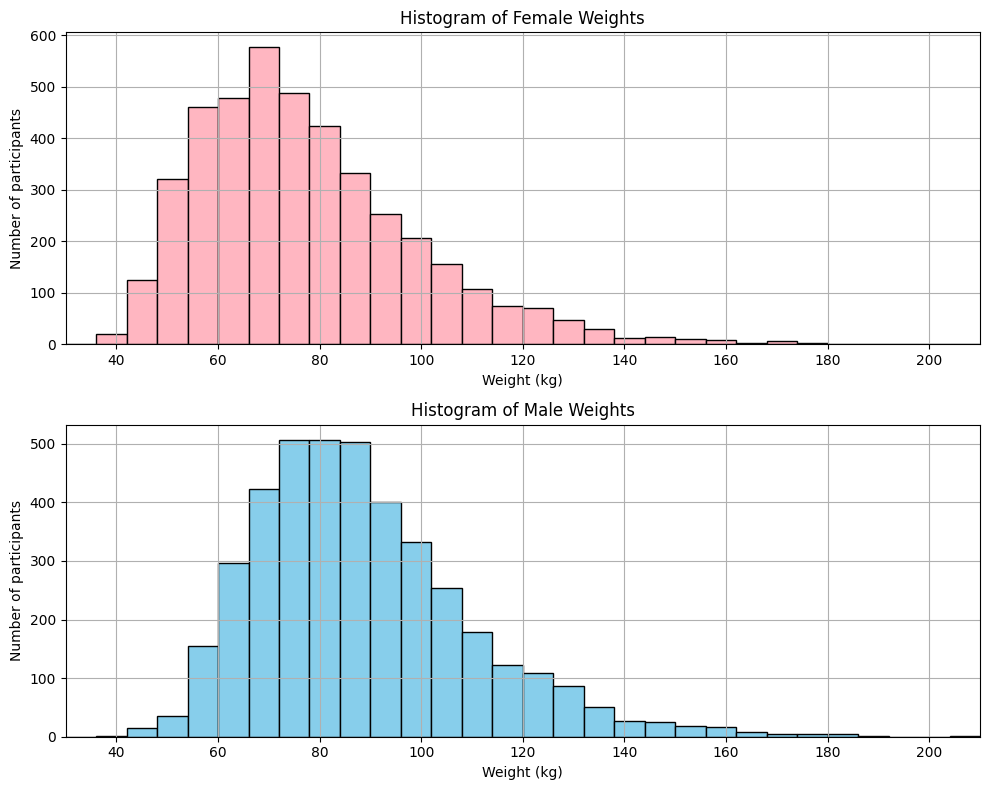

In [6]:
import matplotlib.pyplot as plt

# Weight is column 0 in both matrices
female_weight = female[:, 0]
male_weight = male[:, 0]

# Lowest and highest weight of both groups together
print("Lowest weight :", min(female_weight.min(), male_weight.min()), "kg")
print("Highest weight:", max(female_weight.max(), male_weight.max()), "kg")

# x-axis limits chosen from the values above
x_low = 30
x_high = 210

# One set of bins for both plots: 30, 36, 42, ... 210 (each bar covers 6 kg)
bins = np.arange(30, 211, 6)

# Set the size of the figure
plt.figure(figsize=(10, 8))

# Top plot: female weights
plt.subplot(2, 1, 1)
plt.hist(female_weight, bins=bins, color="lightpink", edgecolor="black")
plt.title("Histogram of Female Weights")
plt.xlabel("Weight (kg)")
plt.ylabel("Number of participants")
plt.xlim(x_low, x_high)
plt.grid()

# Bottom plot: male weights
plt.subplot(2, 1, 2)
plt.hist(male_weight, bins=bins, color="skyblue", edgecolor="black")
plt.title("Histogram of Male Weights")
plt.xlabel("Weight (kg)")
plt.ylabel("Number of participants")
plt.xlim(x_low, x_high)
plt.grid()

# Stop the two plots from overlapping, then show them
plt.tight_layout()
plt.show()

The lightest person weighs 32.6 kg (a woman) and the heaviest 204.6 kg (a man), so the limits of 30 and 210 kg include everybody. Both histograms have one peak and a longer tail on the right: most people are in the middle, and a few are much heavier. The women's peak is in the bar of about 66 to 72 kg, with about 560+ women. The men's top is wider, with three bars of similar height (about 500 men each) between about 72 and 90 kg. The whole men's histogram sits to the right of the women's one, so men are generally heavier. The men's tail also goes further: up to 204.6 kg, against 180.9 kg for women. Both panels use the same axis and bins, so these differences come from the data and not from the way I drew the charts.

## Step 4: Box-and-whisker plot of the weights

A box-and-whisker plot (box plot) shows a group of values in one small picture. The box covers the middle half of the values, from the 25th percentile (a quarter of the people are lighter than this) to the 75th percentile (a quarter are heavier). The line inside the box is the *median*, the middle value: half of the people are lighter and half are heavier. The whiskers go to the furthest values that are within 1.5 times the height of the box, which is the standard rule. Values beyond the whiskers are drawn as single dots. They are called *outliers*: unusually light or heavy people, not necessarily mistakes.

I reuse the weights from Step 3 and give the plot function a list of two groups, women first and men second. This draws two boxes side by side. Then I replace the default labels 1 and 2 with "Female" and "Male". Both boxes share the same vertical scale, so I can compare the centre, the spread and the outliers with just a look.

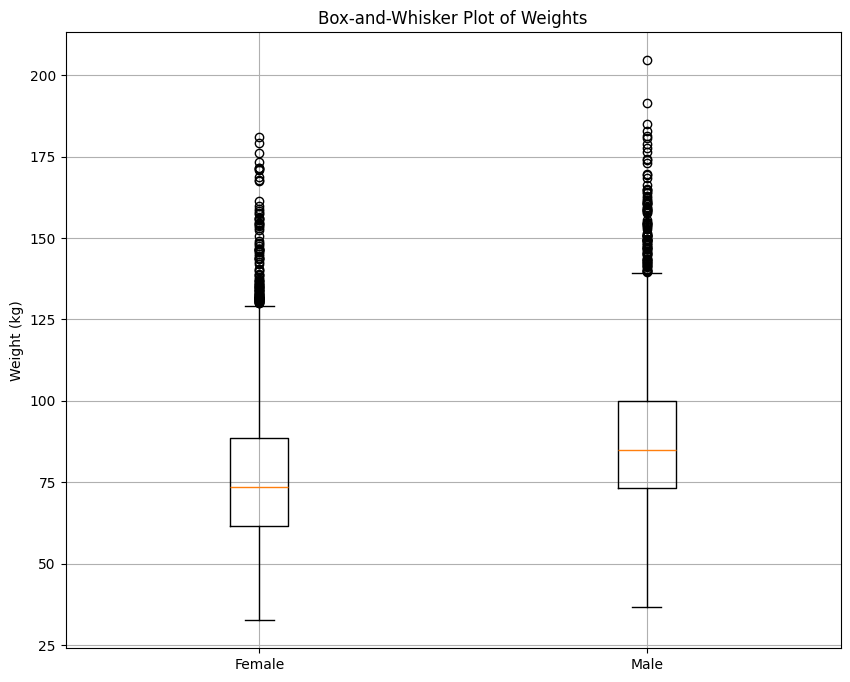

In [7]:
# Weight is column 0 in both matrices
female_weight = female[:, 0]
male_weight = male[:, 0]

# set the figure size
plt.figure(figsize=(10, 8))

# draw two boxes side by side: female first, then male
plt.boxplot([female_weight, male_weight])

# name the two boxes (they are positions 1 and 2)
plt.xticks([1, 2], ["Female", "Male"])
plt.title("Box-and-Whisker Plot of Weights")
plt.ylabel("Weight (kg)")
plt.grid()
plt.show()

The median line of the men's box (about 85 kg) is clearly higher than the women's (about 74 kg), and the whole men's box is shifted up by a similar amount. So the typical man is about 10 kg heavier than the typical woman. The two boxes have almost the same height, so the middle half of each group is spread over a similar range of weights.

In both groups the median line is little closer to the bottom of the box than to the top. All the outliers are on the heavy side, and there are a lot of them, while nobody is below the lower whisker. For women the upper whisker is longer than the lower one, and for men the two whiskers are about equally long. A long run of dots on the heavy side is the typical picture of a right-skewed distribution, where a limited number of very heavy people stretch the upper end. This matches with the historigram above.

## Step 5: Numerical summary of the weights

Charts gives visual data representation here i have described data with three kinds of measures.

- **Location** tells where the centre of the data is. The *mean* is the usual average. The *median* is the middle value when the weights are put in order. The *mode* is the most frequent value.
- **Dispersion** tells how spread out the values are. I report the minimum, the maximum and the *range* (maximum minus minimum). I also report the *quartiles* (the 25th and 75th percentiles) and the *interquartile range* (IQR), which is the distance between them. The IQR shows the spread of the middle half of the data and is not affected by extreme values. Finally I report the *standard deviation*, the typical distance of a value from the mean, and the *variance*, which is its square.
- **Shape** tells how the values are distributed. *Skewness* is 0 for a perfectly symmetric shape, positive if the right tail is longer and negative if the left tail is longer. *Kurtosis* tells whether the tails are heavier or lighter than those of a bell-shaped (normal) curve. I use the "excess" version, which is 0 for a normal curve and positive for heavier tails (NIST/SEMATECH, n.d.; SciPy community, n.d.).

I wrote one function, `summary`, that calculates all these measures for one group. I apply it to the women and to the men and put the results side by side in one table. For the variance and the standard deviation I use the *sample* versions (`ddof=1`), because the participants are a sample of a bigger population.

In [8]:
# Step 5: Numerical summary of male and female weights
from scipy import stats
def mode_of(x):
    # the most frequent value (weights are measured to 0.1 kg)
    values, counts = np.unique(x, return_counts=True)
    return values[counts.argmax()]

def summary(x):
    return {
        # measures of location
        "Mean": np.mean(x),
        "Median": np.median(x),
        "Mode": mode_of(x),
        # measures of dispersion
        "Minimum": np.min(x),
        "Maximum": np.max(x),
        "Range": np.max(x) - np.min(x),
        "25th percentile (Q1)": np.percentile(x, 25),
        "75th percentile (Q3)": np.percentile(x, 75),


        #The Interquartile Range (IQR) measures the spread of the middle 50% of your data,
        #showing how tightly grouped your typical values are while ignoring extreme highs and lows


        "IQR (Q3 - Q1)": np.percentile(x, 75) - np.percentile(x, 25),
        "Variance": np.var(x, ddof=1),               # ddof=1: sample variance
        "Standard deviation": np.std(x, ddof=1),     # ddof=1: sample standard deviation
        # measures of shape
        "Skewness": stats.skew(x),
        "Kurtosis (excess)": stats.kurtosis(x),
    }

weight_summary = pd.DataFrame({"Female": summary(female_weight),
                               "Male": summary(male_weight)})
weight_summary.round(2)

,Female,Male
Mean,77.40,88.36
Median,73.60,85.00
Mode,75.80,79.00
Minimum,32.60,36.80
Maximum,180.90,204.60
Range,148.30,167.80
25th percentile (Q1),61.60,73.30
75th percentile (Q3),88.70,99.80
IQR (Q3 - Q1),27.10,26.50
Variance,464.19,458.88


**Location.** The mean weight is 77.40 kg for women and 88.36 kg for men, a difference of about 11 kg. The medians say the same: 73.60 kg and 85.00 kg, a difference of 11.4 kg. In both groups the mean is above the median (by 3.80 kg for women and 3.36 kg for men). This is typical for a right-skewed distribution, where a few very heavy people pull the average up. The modes (75.80 kg and 79.00 kg) are less useful, because they are just single repeated values.

**Dispersion.** The two groups are spread out almost equally. The standard deviation is 21.55 kg for women and 21.42 kg for men, the variance is 464.19 and 458.88, and the IQR is 27.10 kg and 26.50 kg. Women are slightly higher on all three, but the differences are tiny. The range is bigger for men (167.8 kg against 148.3 kg), but that comes from a few extreme weights, like the maximum of 204.6 kg. So neither group is clearly more variable. The quartiles show that the men's distribution is basically the women's one moved upwards: Q1 is 73.30 kg against 61.60 kg, and Q3 is 99.80 kg against 88.70 kg.

**Shape.** Skewness is positive in both groups (1.03 for women and 0.98 for men), which confirms the longer right tail seen in the histograms and box plots. Excess kurtosis is also positive (1.40 and 1.47), so the tails are heavier than those of a normal curve: there are more very heavy people than a bell-shaped model would expect.

Overall, the two distributions have a similar spread and shape. The main difference is the location: men are about 11 kg heavier at the centre.

## Step 6: Body mass index (BMI) of the female participants

BMI compares a person's weight with their height: BMI = weight in kilograms ÷ (height in metres)², in kg/m². A weight of 80 kg means something different for a person who is 150 cm tall and for one who is 190 cm tall, and BMI tries to take this into account. The CDC groups adult BMI into four categories: below 18.5 is underweight, 18.5 up to 25 is healthy weight, 25 up to 30 is overweight, and 30 or more is obesity (CDC, n.d.). The CDC says that BMI is a screening tool and not a diagnosis. Here I calculate the BMI of every woman and add it to the female matrix as an eighth column.


* The file stores height in centimetres, so I first divide by 100 to get metres.
* NumPy does a calculation on every row at once, so one line gives the BMI of all 4,221 women.
* `np.column_stack` attaches the new column on the right. The code first keeps only the first seven columns and then adds BMI, so running the cell twice does not add the column twice.
* I print the new shape, the first three rows, and the lowest, highest and average BMI as a check.

In [9]:
# Step 6: Body mass index (BMI) as the 8th column of the female matrix
# BMI = weight (kg) / height (m) squared

f_HeightM = female[:, 1] / 100            # change height from cm to metres
f_bmi = female[:, 0] / f_HeightM ** 2

# keep the first 7 columns and add BMI after them (safe to run again)
female = np.column_stack((female[:, :7], f_bmi))

print("female shape:", female.shape)
print()
print("First 3 rows:\n", female[:3].round(2))
print()
print("BMI: \nlowest", f_bmi.min().round(1), "\nhighest", f_bmi.max().round(1),
      "\naverage", f_bmi.mean().round(1))

female shape: (4221, 8)

First 3 rows:
 [[ 97.1  160.2   34.7   40.8   35.8  126.1  117.9   37.84]
 [ 91.1  152.7   33.5   33.    38.5  125.5  103.1   39.07]
 [ 73.   161.2   37.4   38.    31.8  106.2   92.    28.09]]

BMI: 
lowest 14.2 
highest 67.0 
average 30.1


The female matrix now has shape (4221, 8), so BMI is column 7. I checked the first woman by hand: 97.1 kg divided by 1.602 m squared is about 37.8, which matches the 37.84 printed. Across all women, BMI goes from 14.2 to 67.0, and the average is 30.1. The CDC says a BMI below 18.5 is underweight, 30 or more is obesity, and 40 or more is the most severe class of obesity. So the lowest value is underweight, the highest is far above 40, and the average is just above the obesity limit of 30.

## Step 7: Standardising the female measurements (z-scores)

The measurements are in different units (kg, cm, BMI points), so they cannot be compared directly. Standardising changes each value into a **z-score**:

z = (value − mean) / standard deviation

A z-score of 0 is exactly average, a positive one is above average and a negative one is below average. The units are gone, so all columns are on the same scale. The new matrix is called `zfemale`.

1. I take the first 8 columns of `female` (the 7 measurements and BMI).
2. I subtract the column means and divide by the column standard deviations. NumPy does this for all columns at once.
3. As a check, I test that every column of `zfemale` has mean 0 and standard deviation 1.

In [10]:
# Step 7: zfemale = female matrix with every column standardised (z-scores)
# z-score = (value - column average) / column standard deviation

female8 = female[:, :8]        # the 7 measurements + BMI
zfemale = (female8 - female8.mean(axis=0)) / female8.std(axis=0, ddof=1)

print("zfemale shape:", zfemale.shape)
print("First 3 rows:\n", zfemale[:3].round(2))

# Check: every column should now have average 0 and standard deviation 1
print("All column averages are 0:", np.allclose(zfemale.mean(axis=0), 0))
print("All column standard deviations are 1:", np.allclose(zfemale.std(axis=0, ddof=1), 1))

zfemale shape: (4221, 8)
First 3 rows:
 [[ 0.91  0.01 -0.57  1.13  0.55  1.08  1.12  1.  ]
 [ 0.64 -1.05 -1.08 -1.29  1.03  1.04  0.27  1.16]
 [-0.2   0.15  0.58  0.26 -0.16 -0.19 -0.37 -0.26]]
All column averages are 0: True
All column standard deviations are 1: True


`zfemale` has shape (4221, 8), the same as `female`, and both checks print `True`, so every column has mean 0 and standard deviation 1. The first woman has almost exactly average height (z = 0.01) but is heavier than average (weight z = 0.91), with hip and waist about one standard deviation above average (1.08 and 1.12) and a BMI z-score of 1.00. The second woman is shorter than average (z = −1.05), but her BMI is 1.16 standard deviations above average. The third woman is close to average in everything (all her values are between −0.37 and 0.58). Standardising changes only the scale, not the pattern in the data.

## Step 8: Relationships between the measurements

I look at how five standardised measurements of the women (height, weight, waist, hip and BMI) are related. A *scatter plot* shows one dot per woman, placed by two measurements. A *correlation coefficient* gives the same information as one number between −1 and +1: near +1 means both rise together, near 0 means no clear link, and near −1 means one rises when the other falls. I use two kinds. *Pearson's* measures how close the dots are to a straight line. *Spearman's* uses only the rank order of the values, so it is less affected by extreme values (Schober et al., 2018). If both agree, I can trust the result more.

1. From `zfemale` I pick the five columns (positions 1, 0, 6, 5 and 7) and give them names in the same order.
2. I draw a 5 × 5 grid of small plots (a scatterplot matrix). Each square off the diagonal shows one pair of measurements, and the diagonal shows the histogram of each measurement. The dots are small and half-transparent, so crowded areas look darker.
3. Pearson's coefficients come from `np.corrcoef` and Spearman's from `stats.spearmanr` (NumPy Developers, n.d.; SciPy community, n.d.). The rows and columns are in the order Height, Weight, Waist, Hip, BMI.
4. Standardising does not change either coefficient, so the values are the same as for the original measurements.

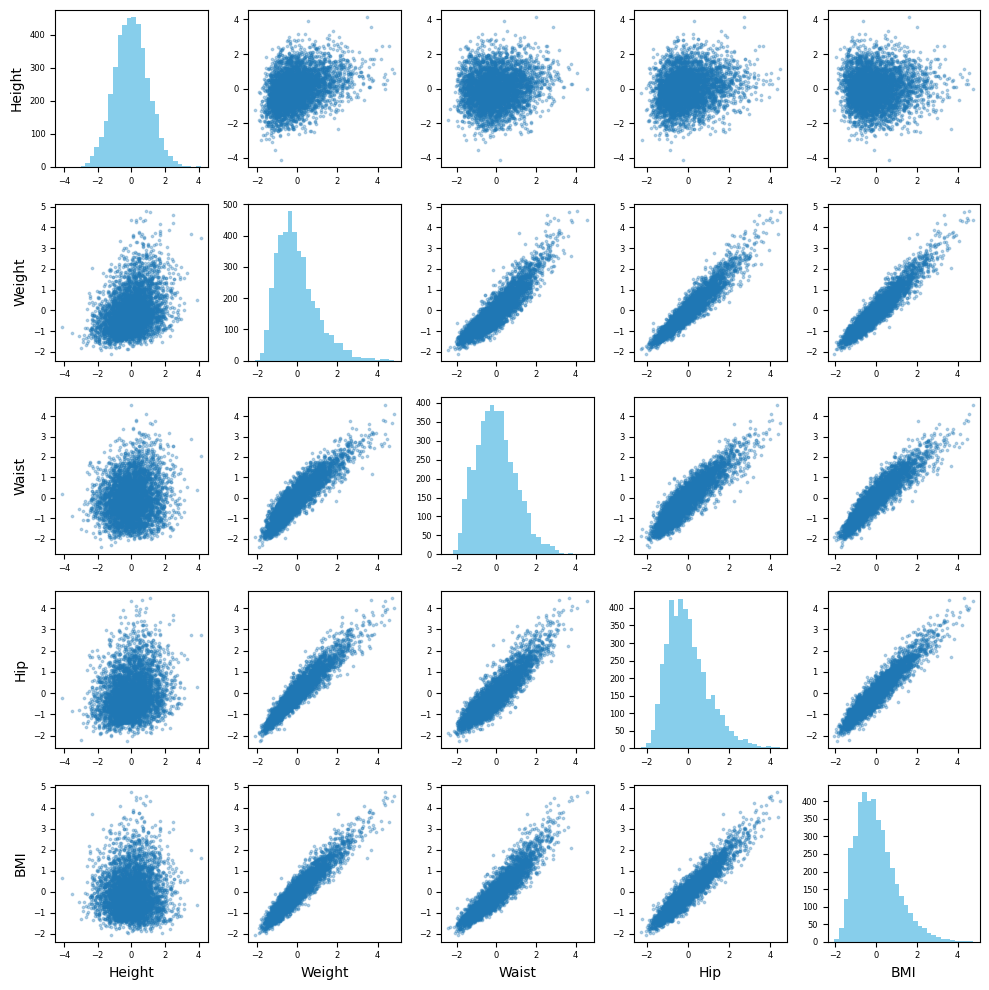


Pearson correlation:
 [[1.   0.35 0.13 0.2  0.03]
 [0.35 1.   0.9  0.95 0.95]
 [0.13 0.9  1.   0.9  0.92]
 [0.2  0.95 0.9  1.   0.94]
 [0.03 0.95 0.92 0.94 1.  ]]

Spearman correlation:
 [[1.   0.34 0.11 0.21 0.02]
 [0.34 1.   0.9  0.95 0.94]
 [0.11 0.9  1.   0.89 0.92]
 [0.21 0.95 0.89 1.   0.93]
 [0.02 0.94 0.92 0.93 1.  ]]


In [11]:
# Step 8: Scatterplot matrix and correlations (standardised female data, no pandas)
# Columns of zfemale: 0 weight, 1 height, 5 hip, 6 waist, 7 BMI

# Pick the five variables and name them
z5 = zfemale[:, [1, 0, 6, 5, 7]]
names = ["Height", "Weight", "Waist", "Hip", "BMI"]

# Scatterplot matrix: a 5 x 5 grid of small plots
plt.figure(figsize=(10, 10))
for row in range(5):
    for col in range(5):
        plt.subplot(5, 5, row * 5 + col + 1)
        if row == col:
            plt.hist(z5[:, col], bins=30, color="skyblue")           # diagonal: histogram
        else:
            plt.scatter(z5[:, col], z5[:, row], s=3, alpha=0.3)        # others: scatter plot
        plt.tick_params(labelsize=6)
        if row == 4:
            plt.xlabel(names[col])      # names along the bottom edge
        if col == 0:
            plt.ylabel(names[row])      # names along the left edge
plt.tight_layout()
plt.show()

# Pearson correlation for all pairs (rowvar=False: the columns are the variables)
pearson = np.corrcoef(z5, rowvar=False)

# Spearman correlation for all pairs (the [0] picks the correlation matrix)
spearman = stats.spearmanr(z5)[0]


print("\nPearson correlation:\n", pearson.round(2))
print("\nSpearman correlation:\n", spearman.round(2))

Weight, waist and hip grow together, which I expected because they all describe body size. Their Pearson correlations are very high (0.90 to 0.95) and the scatter plots show tight rising bands. Height has only a weak link with weight (0.35), hip (0.20) and waist (0.13), and the dots form round clouds. Height and BMI are almost unrelated (0.03), because BMI is already divided by height squared. The Pearson and Spearman tables are nearly the same (they differ by at most 0.02), so the relationships are steady and not caused by a few outliers.

## Step 9: Waist-to-height and waist-to-hip ratios

BMI says something about overall size but not about where the body carries its weight. So I add two ratios. The *waist-to-height ratio* (WHtR) is waist divided by height, and the *waist-to-hip ratio* (WHR) is waist divided by hip. Both measurements must be in cm, so the ratio has no unit.

* From the table in the overview, height is column 1, hip is column 5 and waist is column 6.
* Dividing columns works row by row, so each person's waist is divided by their own height or hip.
* As in Step 6, the code keeps the earlier columns and adds the new ones, so running the cell twice does not duplicate them. The female matrix goes from 8 to 10 columns and the male matrix from 7 to 9.
* I print the new shapes and the ratios of the first three people in each group.

In [12]:
# Step 9: Waist-to-height ratio and waist-to-hip ratio
# Columns: 1 = height, 5 = hip circumference, 6 = waist circumference

female_whtr = female[:, 6] / female[:, 1]       # waist / height
female_whr = female[:, 6] / female[:, 5]        # waist / hip
male_whtr = male[:, 6] / male[:, 1]
male_whr = male[:, 6] / male[:, 5]

# add the two ratios as new columns (the earlier columns are kept; safe to run again)
female = np.column_stack((female[:, :8], female_whtr, female_whr))
male = np.column_stack((male[:, :7], male_whtr, male_whr))

print("female shape:", female.shape)
print("male shape  :", male.shape)
print("\nFirst 3 rows of female (last 2 columns = waist-to-height, waist-to-hip):\n", female[:3, -2:].round(3))
print("\nFirst 3 rows of male (last 2 columns = waist-to-height, waist-to-hip):\n", male[:3, -2:].round(3))

female shape: (4221, 10)
male shape  : (4081, 9)

First 3 rows of female (last 2 columns = waist-to-height, waist-to-hip):
 [[0.736 0.935]
 [0.675 0.822]
 [0.571 0.866]]

First 3 rows of male (last 2 columns = waist-to-height, waist-to-hip):
 [[0.66  1.113]
 [0.471 0.919]
 [0.591 1.017]]


The shapes are now (4221, 10) for women and (4081, 9) for men. I checked the first row of each by hand. First woman: waist 117.9 cm / height 160.2 cm = 0.736 and waist 117.9 cm / hip 126.1 cm = 0.935. First man: 120.4 / 182.3 = 0.660 and 120.4 / 108.2 = 1.113. All four match the printed values, so the columns were calculated correctly.

## Step 10: Comparing the ratios with box-and-whisker plots

I draw one box plot with four boxes: WHtR for women and men, then WHR for women and men. I read the boxes the same way as in Step 4. I saved the ratios in separate variables in Step 9, so I give the four sets straight to the plot function and label each box. Both ratios are between about 0.4 and 1.2, so they can share one vertical axis. The cell also prints the median of each group, because a number is easier to read than a line.

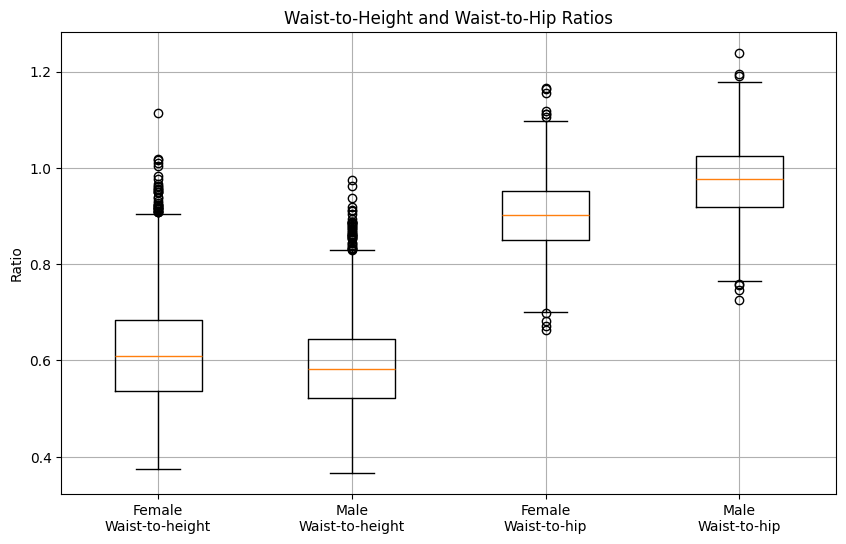

Median waist-to-height: female 0.61 | male 0.582
Median waist-to-hip   : female 0.903 | male 0.977


In [13]:
# Step 10: Box-and-whisker plot of the two ratios for females and males

plt.figure(figsize=(10, 6))
plt.boxplot([female_whtr, male_whtr, female_whr, male_whr])
plt.xticks([1, 2, 3, 4], ["Female\nWaist-to-height", "Male\nWaist-to-height",
                         "Female\nWaist-to-hip", "Male\nWaist-to-hip"])
plt.title("Waist-to-Height and Waist-to-Hip Ratios")
plt.ylabel("Ratio")
plt.grid()
plt.show()

# Median of each group, to help read the plot
print("Median waist-to-height: female", np.median(female_whtr).round(3), "| male", np.median(male_whtr).round(3))
print("Median waist-to-hip   : female", np.median(female_whr).round(3), "| male", np.median(male_whr).round(3))

**Waist-to-height.** Women have a slightly higher median (0.61) than men (0.58), with more spread and higher outliers. NICE says a WHtR below 0.5 is healthy, 0.5 to 0.59 is increased risk and 0.6 or more is high risk (NICE, 2025). The medians of both groups are above 0.5, and so is the lower quartile of both groups.

**Waist-to-hip.** Men have a clearly higher median (0.98) than women (0.90). This fits the usual difference in body shape: men tend to carry more weight around the waist and women more around the hips. The WHO gives high-risk limits of above 0.85 for women and above 0.90 for men (WHO, 2011). The median of each group is above its limit, so more than half of the sample is above it.

## Step 11: Advantages and disadvantages of BMI, WHtR and WHR

**BMI**
* Advantages: it is widely used and needs only weight and height, so it is cheap and fast.
* Disadvantages: it cannot tell muscle from fat, and it does not show where the fat is stored (for example belly fat). It can also be less reliable for older adults and for different ethnic groups.

**Waist-to-height ratio (WHtR)**
* Advantages: it picks up belly fat, and the rule is simple: keep your waist under half your height (ratio below 0.5). Ashwell et al. (2012) found it a better screening tool than BMI.
* Disadvantages: the result depends on measuring the waist at the right place.

**Waist-to-hip ratio (WHR)**
* Advantages: it shows body shape (how fat is distributed), and the WHO has well-known risk limits for it.
* Disadvantages: it needs two tape measurements, so there is more chance of error. Two people of very different size can have the same ratio, for example if they gain weight evenly.

## Step 12: The women with the lowest and highest BMI

I pick the five women with the lowest BMI and the five with the highest BMI and print their z-scores, to see what extreme values look like.

1. `np.argsort` does not sort the BMI values. It gives the *row numbers* that would sort them from smallest to largest (NumPy Developers, n.d.). The first five are the lowest BMIs and the last five are the highest.
2. `zfemale` was made from `female` row by row, so the same row number is the same woman in both matrices.
3. I print the ten rows as the brief asks. A NumPy matrix has no column names, so I also print the names, show the two groups separately and add each woman's real BMI below, to link the z-scores to real values.

In [14]:
# Step 12: Standardised measurements of the 5 lowest and 5 highest BMI females

# argsort gives the row numbers of the BMI column, from lowest BMI to highest BMI
order = np.argsort(female[:, 7])
lowest5 = order[:5]
highest5 = order[-5:]
chosen = np.concatenate((lowest5, highest5))

# the 10 chosen rows of zfemale
print(zfemale[chosen].round(2))

# the same rows, split into the two groups and labelled
names = ["Weight", "Height", "Upper arm length", "Upper leg length",
         "Arm circumference", "Hip circumference", "Waist circumference", "BMI"]
print("\nColumns:", names)

print("\n5 LOWEST BMI (standardised measurements):")
print(zfemale[lowest5].round(2))
print("Actual BMI:", female[lowest5, 7].round(1))

print("\n5 HIGHEST BMI (standardised measurements):")
print(zfemale[highest5].round(2))
print("Actual BMI:", female[highest5, 7].round(1))

[[-2.08 -1.22 -1.55 -1.17 -2.19 -2.04 -1.94 -2.05]
 [-1.88 -0.19 -1.72  0.39 -2.44 -1.85 -2.06 -1.99]
 [-1.54  1.81  0.63  0.57 -2.27 -1.68 -1.71 -1.97]
 [-1.84 -0.26 -0.23  0.51 -2.3  -2.25 -1.86 -1.94]
 [-1.61  0.89 -0.1   0.48 -2.21 -1.83 -1.71 -1.89]
 [ 4.25  0.29  1.86 -0.98  2.37  4.1   3.82  4.4 ]
 [ 4.46  0.5   1.69 -1.14  3.35  3.98  2.9   4.46]
 [ 4.35  0.28  2.84  1.94  4.37  3.92  3.75  4.51]
 [ 4.8   0.89  2.12  1.82  3.78  4.02  4.08  4.54]
 [ 4.36 -0.03 -0.06 -0.17  2.78  4.32  4.57  4.76]]

Columns: ['Weight', 'Height', 'Upper arm length', 'Upper leg length', 'Arm circumference', 'Hip circumference', 'Waist circumference', 'BMI']

5 LOWEST BMI (standardised measurements):
[[-2.08 -1.22 -1.55 -1.17 -2.19 -2.04 -1.94 -2.05]
 [-1.88 -0.19 -1.72  0.39 -2.44 -1.85 -2.06 -1.99]
 [-1.54  1.81  0.63  0.57 -2.27 -1.68 -1.71 -1.97]
 [-1.84 -0.26 -0.23  0.51 -2.3  -2.25 -1.86 -1.94]
 [-1.61  0.89 -0.1   0.48 -2.21 -1.83 -1.71 -1.89]]
Actual BMI: [14.2 14.6 14.8 15.  15.4]

5 HIGHE

The five lowest BMIs (14.2 to 15.4) are all far below the CDC limit for underweight (18.5). Their weight, hip, waist and BMI z-scores are around −2. Their heights go from short (z = −1.22) to tall (z = 1.81), so a low BMI means low weight for the height, not just being short.

The five highest BMIs (64.2 to 67.0) are all far above 40. Their weight and BMI z-scores are over 4, while their heights are close to average. This fits the long right tail from Step 3. Even with almost the same BMI, their waist and arm circumferences differ a lot, so the same BMI can mean different body shapes.

## Conclusion and Limitations

### Conclusion
The sample of 4,081 men and 4,221 women has no missing values. Men are on average about 11 kg heavier than women, but the spread is the same in both groups (standard deviation about 21.5 kg). Weight and waist show a right skew with many heavy outliers.

In women, weight, waist, hip and BMI are strongly correlated (0.90 to 0.95), while height is almost unrelated to BMI (0.03). Women have higher waist-to-height ratios and men have higher waist-to-hip ratios. For both ratios, the medians of both groups are above the recommended limits.

### Limitations
1. The data has no survey weights, so the results describe this sample and cannot be applied to the whole US population.
2. There is no age or ethnicity in the data, and both affect body size and the healthy limits.
3. Some correlations are high partly because of the formulas (BMI and the ratios are calculated from weight, height, waist and hip), not only because of biology.
4. The mean, variance and kurtosis react strongly to extreme weights, so the median and quartiles are safer summaries here.

###References

* Gagolewski, M. (n.d.). teaching-data [Data repository]. GitHub. https://github.com/gagolews/teaching-data (files nhanes_adult_male_bmx_2020.csv and nhanes_adult_female_bmx_2020.csv, folder marek). The files are NHANES body measures from the US CDC.
* Google search on ways to extract data/table from github.
* CDC. (n.d.). Adult BMI categories. https://www.cdc.gov/bmi/adult-calculator/bmi-categories.html
* NICE. (2025). Overweight and obesity management (NG246). https://www.nice.org.uk/guidance/NG246/chapter/Identifying-and-assessing-overweight-obesity-and-central-adiposity
* WHO. (2011). Waist circumference and waist-hip ratio: report of a WHO expert consultation. https://www.who.int/publications/i/item/9789241501491
* Ashwell, M., Gunn, P., & Gibson, S. (2012). Waist-to-height ratio is a better screening tool than waist circumference and BMI for adult cardiometabolic risk factors: systematic review and meta-analysis. Obesity Reviews, 13(3), 275-286. https://doi.org/10.1111/j.1467-789X.2011.00952.x
* NIST/SEMATECH. (n.d.). Measures of skewness and kurtosis. In e-Handbook of Statistical Methods. https://www.itl.nist.gov/div898/handbook/eda/section3/eda35b.htm
* Schober, P., Boer, C., & Schwarte, L. A. (2018). Correlation coefficients: appropriate use and interpretation. Anesthesia & Analgesia, 126(5), 1763-1768. https://doi.org/10.1213/ANE.0000000000002864
* NumPy Developers. (n.d.). numpy.corrcoef and numpy.argsort. https://numpy.org/doc/stable/reference/generated/numpy.corrcoef.html
* SciPy community. (n.d.). scipy.stats.spearmanr, skew and kurtosis. https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.spearmanr.html
* pandas development team. (n.d.). pandas.read_csv. https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html
* Python Software Foundation. (n.d.). urllib.request. https://docs.python.org/3/library/urllib.request.html

I used AI assistants as a study aid while preparing this project, mainly gemini . I used it to explain statistical ideas and Python functions, to suggest how to structure the report, to help find and summarise background sources, and to help draft and proofread the text and help with references.